# One-Hot Encoding on the Used-Car Dataset

This notebook independently loads `cars.csv` and follows the same analysis as the companion ordinal-encoding notebook. It encodes the same categorical columns—`brand`, `fuel`, and `owner`—with one-hot indicators, visualizes distributions and price relationships, and examines encoded-feature correlations.

One-hot encoding is appropriate for the nominal `brand` and `fuel` columns because it does not invent an ordering. `owner` has a meaningful owner-count order, but one-hot encoding is still useful when we do not want a model to assume equally spaced numeric steps. “Test Drive Car” is included as its own category.

Run the cells from top to bottom. The CSV should be beside this notebook, as in the supplied `feature-engineering/encoding` folder.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

# Support both running from the notebook's folder and from a project root.
search_roots = [Path.cwd(), *Path.cwd().parents]
candidates = [root / "cars.csv" for root in search_roots]
candidates += [root / "feature-engineering" / "encoding" / "cars.csv" for root in search_roots]
DATA_PATH = next((path for path in candidates if path.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Could not find cars.csv. Place it beside this notebook or run from the project tree.")

df = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Loaded /Users/srinivasaraotadela/Documents/ml/feature-engineering/encoding/cars.csv
Shape: 8,128 rows × 5 columns


,brand,km_driven,fuel,owner,selling_price
0,Maruti,145500,Diesel,First Owner,450000
1,Skoda,120000,Diesel,Second Owner,370000
2,Honda,140000,Petrol,Third Owner,158000
3,Hyundai,127000,Diesel,First Owner,225000
4,Maruti,120000,Petrol,First Owner,130000


## 1. Inspect the real dataset

Check types, missing values, and summary statistics before encoding. `selling_price` is the numeric outcome used in the plots, not an input to encode. We apply one-hot encoding to `brand`, `fuel`, and `owner`; `km_driven` remains numeric.

In [2]:
print("Column names:", df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nSummary statistics (all columns):")
display(df.describe(include="all").T)

categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()
expected_categorical_columns = ["brand", "fuel", "owner"]
if categorical_columns != expected_categorical_columns:
    raise ValueError(f"Expected categorical columns {expected_categorical_columns}, found {categorical_columns}")
target_column = "selling_price"
numeric_predictors = [column for column in df.select_dtypes(include="number").columns if column != target_column]
print("\nCategorical columns used in both notebooks:", categorical_columns)
print("Numeric predictor kept unchanged:", numeric_predictors)
for column in categorical_columns:
    print(f"\n{column}: {df[column].nunique()} categories")
    display(df[column].value_counts(dropna=False).rename("count").to_frame())

Column names: ['brand', 'km_driven', 'fuel', 'owner', 'selling_price']

Data types:
 brand            object
km_driven         int64
fuel             object
owner            object
selling_price     int64
dtype: object

Missing values:
 brand            0
km_driven        0
fuel             0
owner            0
selling_price    0
dtype: int64

Summary statistics (all columns):


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand,8128,32,Maruti,2448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
km_driven,"8,128.00",NaN,NaN,NaN,"69,819.51","56,550.55",1.00,"35,000.00","60,000.00","98,000.00","2,360,457.00"
fuel,8128,4,Diesel,4402,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,8128,5,First Owner,5289,NaN,NaN,NaN,NaN,NaN,NaN,NaN
selling_price,"8,128.00",NaN,NaN,NaN,"638,271.81","806,253.40","29,999.00","254,999.00","450,000.00","675,000.00","10,000,000.00"



Categorical columns used in both notebooks: ['brand', 'fuel', 'owner']
Numeric predictor kept unchanged: ['km_driven']

brand: 32 categories


,count
brand,
Maruti,2448
Hyundai,1415
Mahindra,772
Tata,734
Toyota,488
Honda,467
Ford,397
Chevrolet,230
Renault,228



fuel: 4 categories


,count
fuel,
Diesel,4402
Petrol,3631
CNG,57
LPG,38



owner: 5 categories


,count
owner,
First Owner,5289
Second Owner,2105
Third Owner,555
Fourth & Above Owner,174
Test Drive Car,5


## 2. Configure one-hot encoding and unseen-category handling

One-hot indicators avoid assigning a numeric rank to nominal values. We reserve explicit `__OTHER__` and `__MISSING__` categories in each feature. Before transformation, missing values are mapped to `__MISSING__`, while category values not observed in this dataset are mapped to `__OTHER__`; this lets future unseen values receive a recognizable indicator instead of silently becoming all-zero rows.

To address the dummy variable trap in a linear model with an intercept, `drop="first"` omits one reference level per source column. All other levels remain interpretable against that reference. The reference level is not a universal baseline of quality—it is simply the first category in each configured list. Reserved categories also ensure missing and other values can be represented; they may be all-zero columns in this current dataset because no such rows are present.

The encoder is fit on all rows here for an encoding tutorial. For predictive evaluation, fit preprocessing on training folds only, preferably in a scikit-learn pipeline.

In [3]:
category_levels = {
    column: sorted(df[column].dropna().unique().tolist())
    for column in categorical_columns
}
OTHER_CATEGORY = "__OTHER__"
MISSING_CATEGORY = "__MISSING__"
for column, levels in category_levels.items():
    if OTHER_CATEGORY in levels or MISSING_CATEGORY in levels:
        raise ValueError(f"A reserved encoding label already appears in {column}.")

def prepare_categories(frame):
    """Map nulls and values unseen during fitting to explicit reserved levels."""
    prepared = frame[categorical_columns].copy()
    for column in categorical_columns:
        known = set(category_levels[column])
        prepared[column] = prepared[column].where(prepared[column].notna(), MISSING_CATEGORY)
        prepared[column] = prepared[column].map(lambda value: value if value in known else OTHER_CATEGORY)
    return prepared

onehot_categories = [
    category_levels[column] + [OTHER_CATEGORY, MISSING_CATEGORY]
    for column in categorical_columns
]
onehot_encoder = OneHotEncoder(
    categories=onehot_categories,
    drop="first",
    handle_unknown="error",  # prepare_categories routes future unknowns into __OTHER__
    sparse_output=False,
    dtype=np.int8,
)
prepared_categories = prepare_categories(df)
encoded_array = onehot_encoder.fit_transform(prepared_categories)
encoded_names = onehot_encoder.get_feature_names_out(categorical_columns)
encoded_df = pd.DataFrame(encoded_array, columns=encoded_names, index=df.index)

print("Configured category levels (one reference level dropped per feature):")
for column, levels in zip(categorical_columns, onehot_categories):
    print(f"{column}: {levels}")
dropped_reference_categories = {
    column: categories[index]
    for column, categories, index in zip(categorical_columns, onehot_encoder.categories_, onehot_encoder.drop_idx_)
}
print("\nDropped reference categories:", dropped_reference_categories)
print("Encoded categorical feature count:", encoded_df.shape[1])
print("Missing values in source data:", int(df[categorical_columns].isna().sum().sum()))

Configured category levels (one reference level dropped per feature):
brand: ['Ambassador', 'Ashok', 'Audi', 'BMW', 'Chevrolet', 'Daewoo', 'Datsun', 'Fiat', 'Force', 'Ford', 'Honda', 'Hyundai', 'Isuzu', 'Jaguar', 'Jeep', 'Kia', 'Land', 'Lexus', 'MG', 'Mahindra', 'Maruti', 'Mercedes-Benz', 'Mitsubishi', 'Nissan', 'Opel', 'Peugeot', 'Renault', 'Skoda', 'Tata', 'Toyota', 'Volkswagen', 'Volvo', '__OTHER__', '__MISSING__']
fuel: ['CNG', 'Diesel', 'LPG', 'Petrol', '__OTHER__', '__MISSING__']
owner: ['First Owner', 'Fourth & Above Owner', 'Second Owner', 'Test Drive Car', 'Third Owner', '__OTHER__', '__MISSING__']

Dropped reference categories: {'brand': 'Ambassador', 'fuel': 'CNG', 'owner': 'First Owner'}
Encoded categorical feature count: 44
Missing values in source data: 0


### Inspect the result and feature count

The preview places source labels beside their indicator columns. `selling_price` is excluded from the feature matrix; it remains the target. Dropping one reference category per input reduces the number of indicators by three compared with keeping every category.

In [4]:
preview = pd.concat(
    [df[categorical_columns].head().add_suffix(" (original)"), encoded_df.head()],
    axis=1,
)
display(preview)

X_onehot = pd.concat([df[numeric_predictors], encoded_df], axis=1)
original_predictor_count = len(numeric_predictors) + len(categorical_columns)
encoded_predictor_count = X_onehot.shape[1]
print(f"Predictor features before encoding: {original_predictor_count}")
print(f"Predictor features after one-hot encoding: {encoded_predictor_count}")
print(f"Encoded feature matrix shape (target excluded): {X_onehot.shape}")
print("One-hot indicators per original column:", dict(zip(categorical_columns, [len(levels) - 1 for levels in onehot_categories])))

# Demonstrate the same mapping used for future missing or unseen input values.
probe = pd.DataFrame({"brand": ["Unlisted Brand"], "fuel": [np.nan], "owner": ["New Owner"]})
prepared_probe = prepare_categories(probe)
probe_encoded = onehot_encoder.transform(prepared_probe)
print("\nUnseen/missing input mapped to reserved categories:")
display(prepared_probe)
display(pd.DataFrame(probe_encoded, columns=encoded_names))

,brand (original),fuel (original),owner (original),brand_Ashok,brand_Audi,brand_BMW,brand_Chevrolet,brand_Daewoo,brand_Datsun,brand_Fiat,brand_Force,brand_Ford,brand_Honda,brand_Hyundai,brand_Isuzu,brand_Jaguar,brand_Jeep,brand_Kia,brand_Land,brand_Lexus,brand_MG,brand_Mahindra,brand_Maruti,brand_Mercedes-Benz,brand_Mitsubishi,brand_Nissan,brand_Opel,brand_Peugeot,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen,brand_Volvo,brand___OTHER__,brand___MISSING__,fuel_Diesel,fuel_LPG,fuel_Petrol,fuel___OTHER__,fuel___MISSING__,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner,owner___OTHER__,owner___MISSING__
0,Maruti,Diesel,First Owner,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
1,Skoda,Diesel,Second Owner,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0
2,Honda,Petrol,Third Owner,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0
3,Hyundai,Diesel,First Owner,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
4,Maruti,Petrol,First Owner,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0


Predictor features before encoding: 4
Predictor features after one-hot encoding: 45
Encoded feature matrix shape (target excluded): (8128, 45)
One-hot indicators per original column: {'brand': 33, 'fuel': 5, 'owner': 6}

Unseen/missing input mapped to reserved categories:


,brand,fuel,owner
0,__OTHER__,__OTHER__,__OTHER__


,brand_Ashok,brand_Audi,brand_BMW,brand_Chevrolet,brand_Daewoo,brand_Datsun,brand_Fiat,brand_Force,brand_Ford,brand_Honda,brand_Hyundai,brand_Isuzu,brand_Jaguar,brand_Jeep,brand_Kia,brand_Land,brand_Lexus,brand_MG,brand_Mahindra,brand_Maruti,brand_Mercedes-Benz,brand_Mitsubishi,brand_Nissan,brand_Opel,brand_Peugeot,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen,brand_Volvo,brand___OTHER__,brand___MISSING__,fuel_Diesel,fuel_LPG,fuel_Petrol,fuel___OTHER__,fuel___MISSING__,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner,owner___OTHER__,owner___MISSING__
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0


## 3. Visualize category distributions before encoding

These count plots show the original category frequencies. They provide context for why one-hot encoding can produce many mostly-zero indicator columns, particularly for the 32 distinct brands.

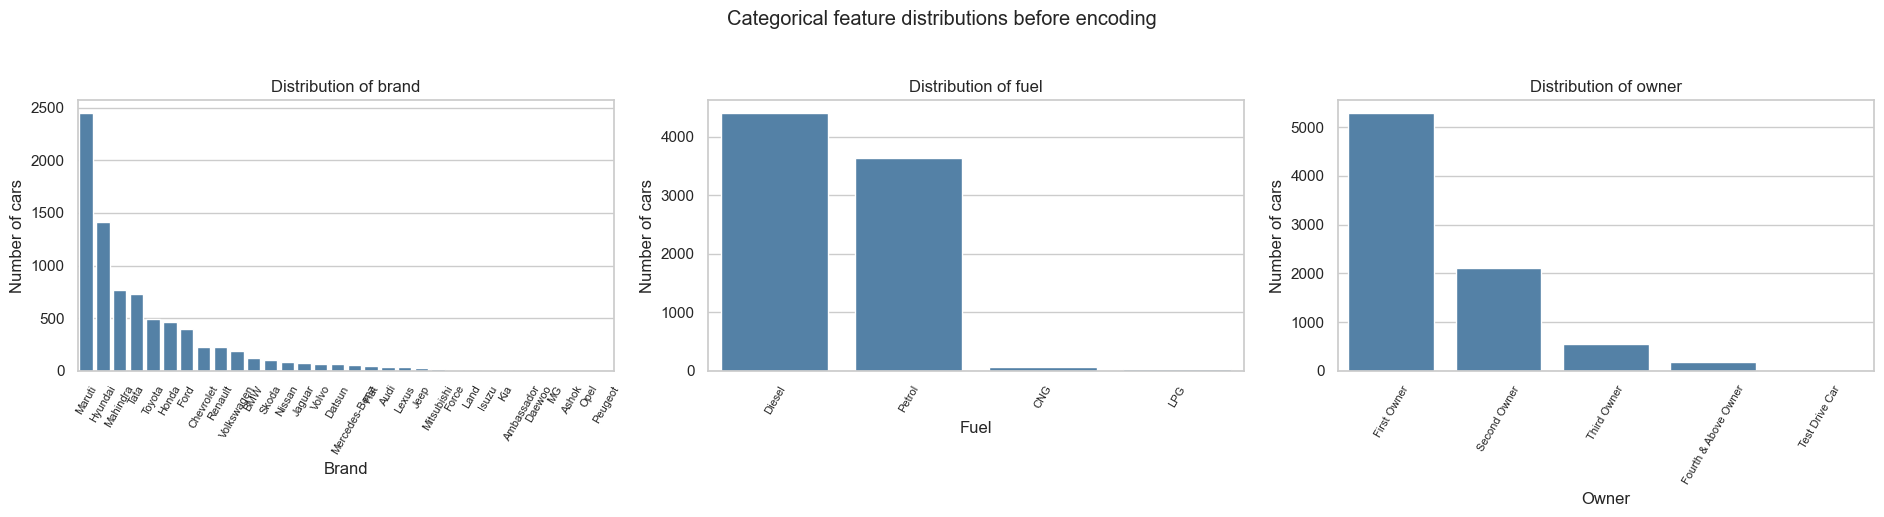

In [5]:
fig, axes = plt.subplots(1, len(categorical_columns), figsize=(19, 5))
for ax, column in zip(axes, categorical_columns):
    order = df[column].value_counts().index
    sns.countplot(data=df, x=column, order=order, color="steelblue", ax=ax)
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Number of cars")
    ax.tick_params(axis="x", labelrotation=60, labelsize=8)
fig.suptitle("Categorical feature distributions before encoding", y=1.03)
fig.tight_layout()
plt.show()

**Interpretation:** the brand feature contains many more distinct levels than fuel or owner, with a few common brands and numerous rare ones. Fuel is dominated by Diesel and Petrol, and most cars are First Owner. One-hot encoding preserves these distinctions without ordering them, but allocates an indicator for each configured level.

## 4. Compare price across the original categories

The price plots use original labels so the interpretation is independent of encoded column names. A logarithmic price axis makes central distributions easier to compare despite the target's long right tail. Fliers are hidden for readability, not removed from the dataset.

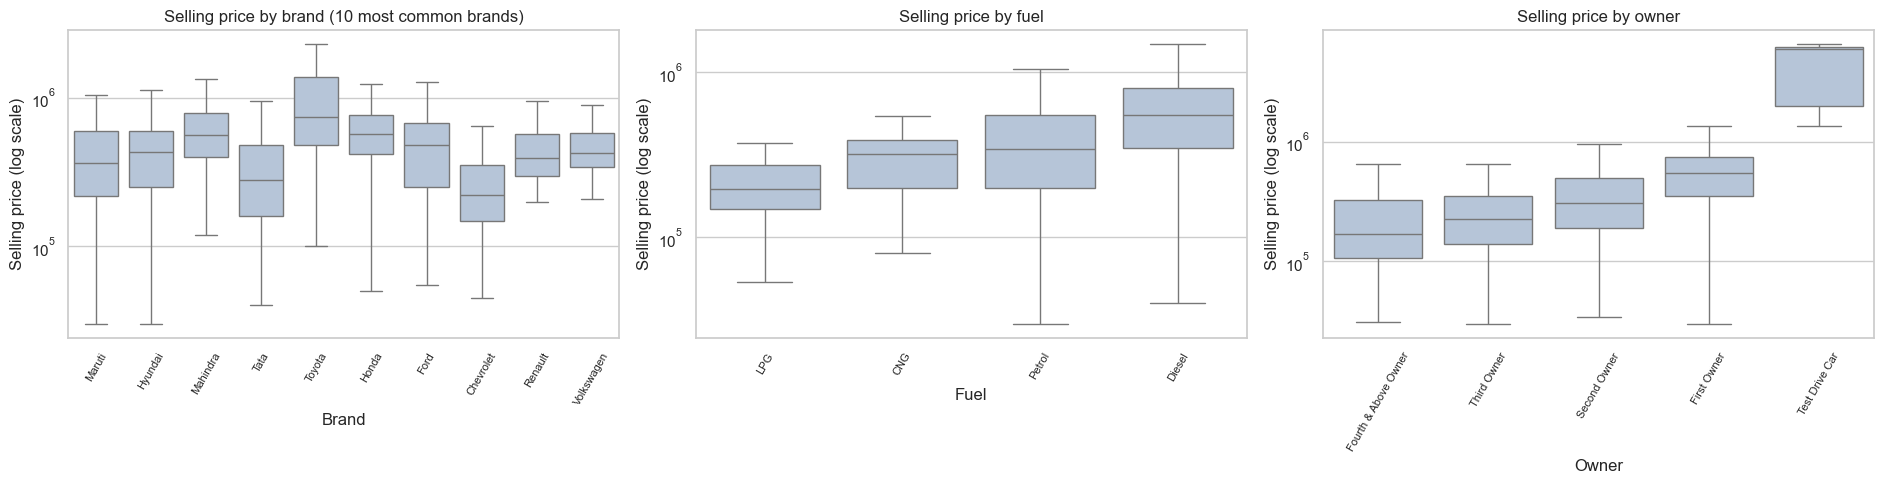

In [6]:
fig, axes = plt.subplots(1, len(categorical_columns), figsize=(19, 5))
for ax, column in zip(axes, categorical_columns):
    if column == "brand":
        order = df[column].value_counts().head(10).index
        plot_df = df[df[column].isin(order)]
        title_suffix = " (10 most common brands)"
    else:
        plot_df = df
        order = df.groupby(column)[target_column].median().sort_values().index
        title_suffix = ""
    sns.boxplot(data=plot_df, x=column, y=target_column, order=order, showfliers=False, color="lightsteelblue", ax=ax)
    ax.set_yscale("log")
    ax.set_title(f"Selling price by {column}{title_suffix}")
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Selling price (log scale)")
    ax.tick_params(axis="x", labelrotation=60, labelsize=8)
fig.tight_layout()
plt.show()

**Interpretation:** selling-price distributions differ across fuel and owner groups and across the ten most frequent brands, so these features may help explain price. There is considerable within-category variation and overlap. Rare categories need cautious interpretation because their price estimates rely on few cars.

## 5. Visualize the change in predictor dimensionality

One-hot encoding expands each categorical input into indicator features. The numeric `km_driven` column remains unchanged, and the target is excluded. With three dropped reference categories, the encoded width is smaller than the full set of configured levels, but much larger than the original three categorical columns.

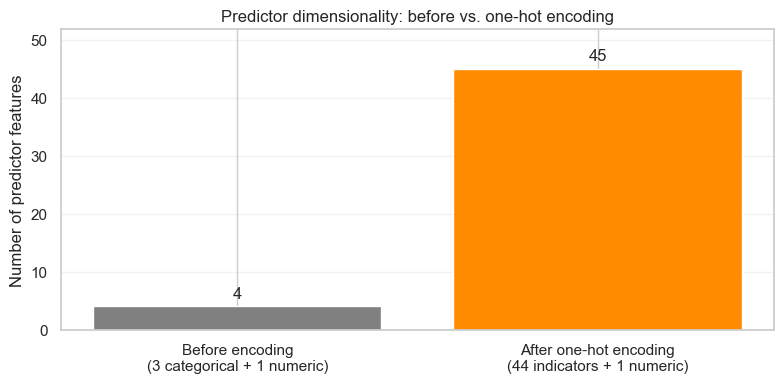

In [7]:
counts = [original_predictor_count, encoded_predictor_count]
labels = ["Before encoding\n(3 categorical + 1 numeric)", f"After one-hot encoding\n({encoded_df.shape[1]} indicators + 1 numeric)"]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, counts, color=["gray", "darkorange"])
ax.bar_label(bars, padding=4)
ax.set_ylabel("Number of predictor features")
ax.set_title("Predictor dimensionality: before vs. one-hot encoding")
ax.set_ylim(0, max(counts) * 1.15)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation:** the predictor matrix grows from four columns to dozens because each brand, fuel, and owner level gets an indicator (with one reference level omitted per source feature). This avoids false numeric order, but increases memory use and can produce sparse features. The reserved `__OTHER__` and `__MISSING__` indicators are currently all zero because this CSV contains neither missing values nor unseen levels.

## 6. Correlation heatmap of encoded features

This heatmap includes all one-hot encoded features, including the reserved `Other` and `Missing` indicators. Mutually exclusive indicators from the same source column are expected to be negatively correlated; rare levels may also have weak-looking correlations simply because they occur infrequently. The target is intentionally excluded from this feature-to-feature heatmap.

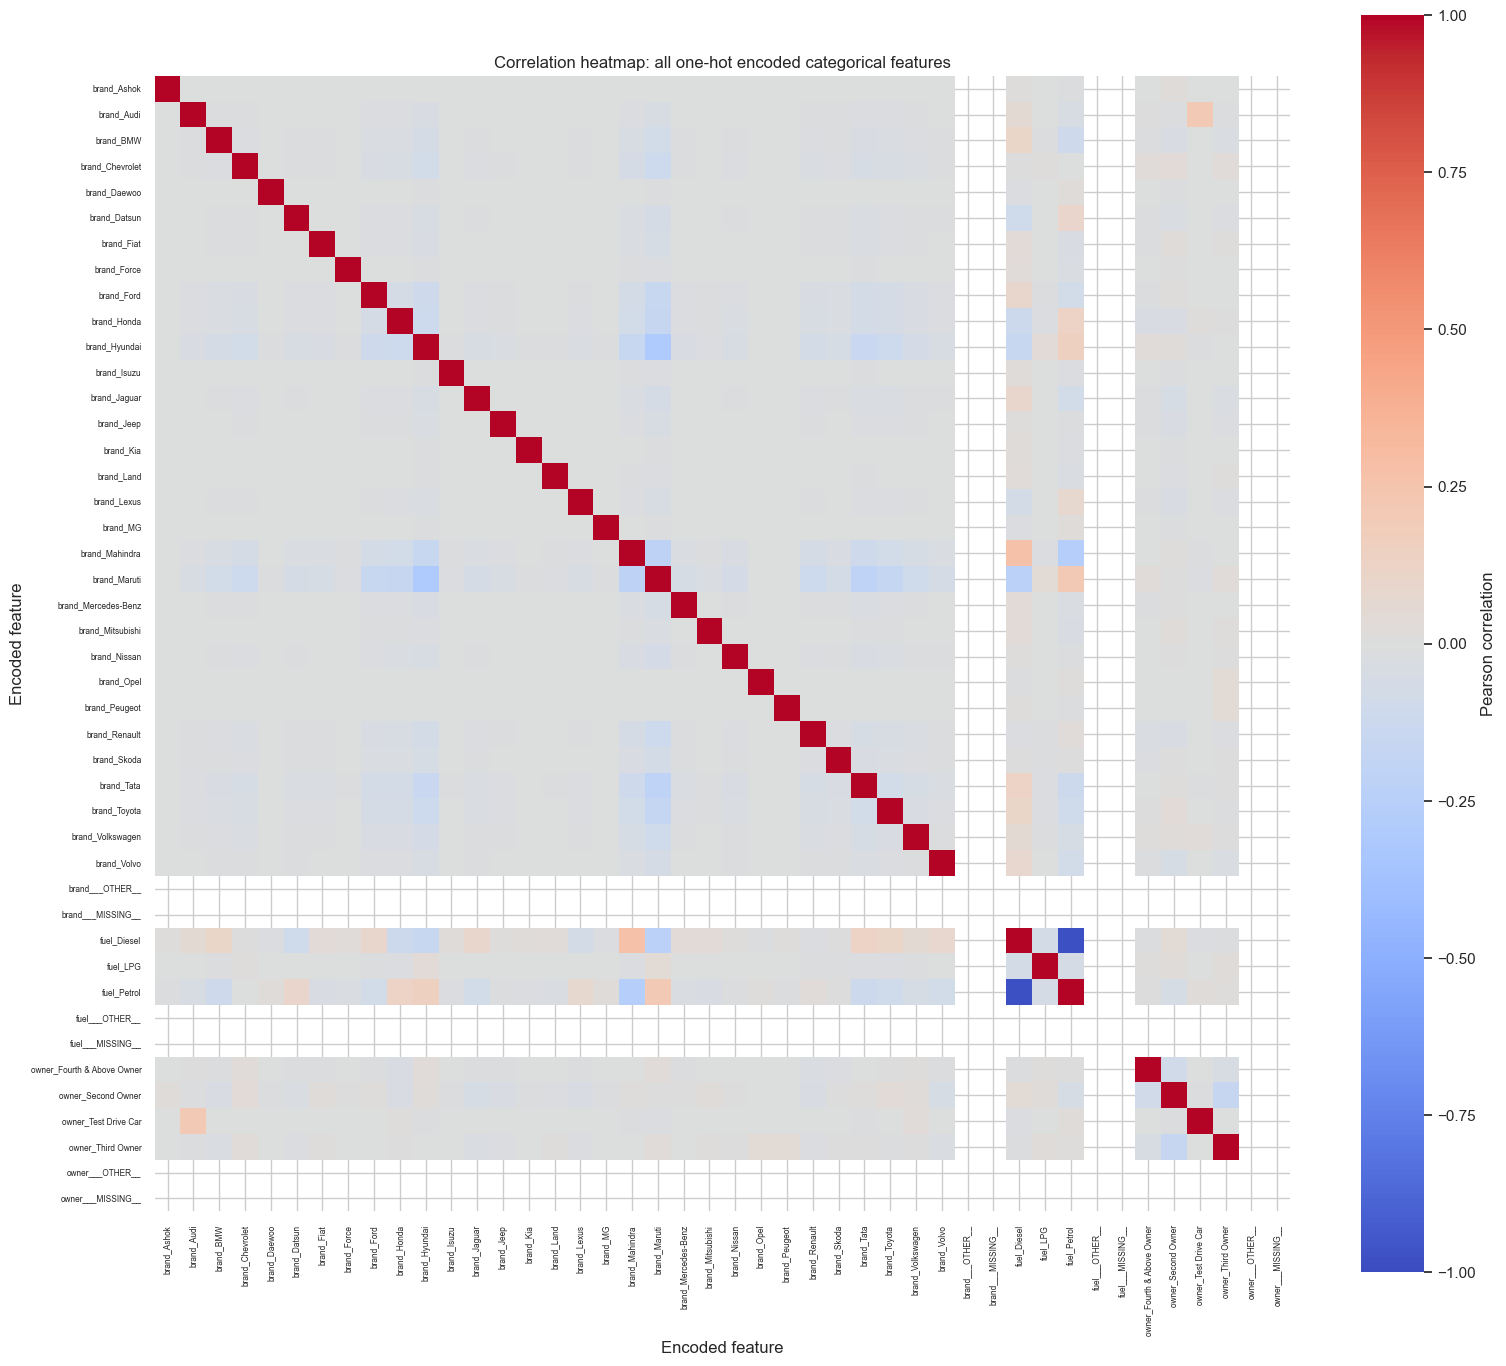

In [8]:
onehot_correlations = encoded_df.corr()
fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(
    onehot_correlations,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={"label": "Pearson correlation"},
    ax=ax,
)
ax.set_title("Correlation heatmap: all one-hot encoded categorical features")
ax.set_xlabel("Encoded feature")
ax.set_ylabel("Encoded feature")
ax.tick_params(axis="x", labelrotation=90, labelsize=6)
ax.tick_params(axis="y", labelrotation=0, labelsize=6)
plt.tight_layout()
plt.show()

**Interpretation:** the blocks of negative correlation among indicators from the same original feature arise because a car belongs to only one category within that feature. Correlations between different feature groups can reflect co-occurrence patterns, but do not establish causal effects on price. Constant reserved columns may produce undefined correlations shown as blank cells.

## 7. Conclusion: when is one-hot encoding appropriate here?

**Strengths:** it represents `brand` and `fuel` without imposing an artificial order, and also avoids assuming equal numeric spacing between owner categories. It is widely compatible with linear and distance-based estimators. Reserved missing/other indicators make exceptional values explicit, while `handle_unknown="error"` helps catch a failure to map them before encoding.

**Weaknesses:** the representation increases dimensionality (especially for the 32 brands), may be sparse, and dropped reference levels need to be understood when interpreting coefficients. Very rare categories can produce estimates based on few records. The mapping step should be reused unchanged in production.

**Recommendation for this dataset:** one-hot encoding is the more defensible general-purpose choice for nominal `brand` and `fuel`, and is a safe choice for `owner` when you do not want to impose an ordinal relationship. For a dataset with many more brands, consider grouping genuinely rare categories or using a model with native categorical support. Fit preprocessing on training folds only in any predictive workflow.